# DriftWise: Main experiments (EGA)
Cleaned notebook. Run cells top to bottom. Older exploration steps are in `DriftWise_Archive_exploration.ipynb`; the UNSW-NB15 audit is in `DriftWise_UNSW_audit.ipynb`.

## 1. Install packages
Run this first, then **Runtime → Restart session**, then continue from the next cell.

In [ ]:
!pip install river "numpy<2.3" -q

## 2. Setup: Drive, folders, environment

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

# DriftWise: Environment Check

import sys
import os
import platform

print("Project: DriftWise")
print("Python version:", sys.version)
print("Operating system:", platform.system())

project_path = "/content/drive/MyDrive/DriftWise"

os.makedirs(project_path, exist_ok=True)

print("Drive folder exists:", os.path.exists(project_path))
print("Project path:", project_path)


Project: DriftWise
Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Operating system: Linux
Drive folder exists: True
Project path: /content/drive/MyDrive/DriftWise


In [ ]:

import os

project_path = "/content/drive/MyDrive/DriftWise"

folders = [
    "data/raw",
    "data/processed",
    "notebooks",
    "src",
    "results/metrics",
    "results/plots",
    "models",
    "configs",
    "paper",
    "logs"
]

for folder in folders:
    path = os.path.join(project_path, folder)
    os.makedirs(path, exist_ok=True)

print("DriftWise folder structure created successfully!")

for folder in folders:
    print(folder)


DriftWise folder structure created successfully!
data/raw
data/processed
notebooks
src
results/metrics
results/plots
models
configs
paper
logs


In [ ]:
import os
import psutil
import platform

print("Operating system:", platform.system())
print("CPU cores:", os.cpu_count())
print("Total RAM (GB):", round(
    psutil.virtual_memory().total / (1024**3), 2
))
print("Available RAM (GB):", round(
    psutil.virtual_memory().available / (1024**3), 2
))

print("\nGPU information:")
try:
    import subprocess
    result = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True
    )
    if result.returncode == 0:
        print(result.stdout)
    else:
        print("No NVIDIA GPU available in this session.")
except FileNotFoundError:
    print("No NVIDIA GPU available in this session.")


Operating system: Linux
CPU cores: 2
Total RAM (GB): 12.67
Available RAM (GB): 11.12

GPU information:
Sun Nov  1 03:20:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                    

In [ ]:
import numpy, sklearn, river
print("numpy", numpy.__version__, "| sklearn", sklearn.__version__, "| river", river.__version__)

numpy 2.2.6 | sklearn 1.6.1 | river 0.26.1


## 3. Stream v2 and the sequential gate
Regenerates stream v2 and writes `src/ega_gate.py`.

In [ ]:
import os
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier

# 1) Create the project folders in My Drive
base = "/content/drive/MyDrive/DriftWise"
for sub in ["data/processed", "results/plots", "src"]:
    os.makedirs(f"{base}/{sub}", exist_ok=True)

# 2) Regenerate stream v2 (identical to Step 8: seed 42)
feats = ["feature_1", "feature_2"]
rng = np.random.default_rng(42)
n_records, drift_point = 10000, 5000
p_attack = np.where(np.arange(n_records) < drift_point, 0.05, 0.20)
y2 = (rng.random(n_records) < p_attack).astype(int)
X2 = rng.normal(size=(n_records, 2))
X2[:drift_point, 0] += 2.0 * y2[:drift_point]
X2[drift_point:, 1] += 2.0 * y2[drift_point:]
synthetic_v2 = pd.DataFrame(X2, columns=feats)
synthetic_v2["Label"] = y2
synthetic_v2["stream_index"] = np.arange(n_records)
synthetic_v2.to_csv(f"{base}/data/processed/synthetic_stream_v2.csv", index=False)

# 3) Refit the frozen old model on records 0-3999
old_sc = StandardScaler()
old_m = SGDClassifier(loss="log_loss", class_weight="balanced", random_state=42)
old_m.fit(old_sc.fit_transform(synthetic_v2.iloc[:4000][feats]), synthetic_v2.iloc[:4000]["Label"])

# 4) Write the sequential gate file
gate_code = '''
import numpy as np
from math import pi
from scipy.stats import norm


def alpha_for_look(look, alpha_total=0.05):
    return alpha_total * 6.0 / (pi ** 2 * look ** 2)


def _lower_bound(diffs_by_class, z):
    est, var = 0.0, 0.0
    k = len(diffs_by_class)
    for d in diffs_by_class:
        est += d.mean() / k
        var += (d.var(ddof=1) / len(d)) / (k ** 2)
    return est, est - z * np.sqrt(max(var, 1e-12))


def sequential_gate(y, p_new, p_old, look, alpha_total=0.05,
                    min_n=200, min_per_class=30,
                    delta_overall=0.01, delta_class=0.03,
                    min_effect=0.0, cost_penalty=0.0, guard_all_classes=False):
    y, p_new, p_old = map(np.asarray, (y, p_new, p_old))
    a = alpha_for_look(look, alpha_total)
    z = norm.ppf(1 - a)

    classes = np.unique(y)
    counts = {int(c): int((y == c).sum()) for c in classes}
    enough = len(y) >= min_n and len(classes) == 2 and all(n >= min_per_class for n in counts.values())
    out = {"look": look, "alpha_spent": a, "n": len(y), "counts": counts}
    if not enough:
        out.update(decision="DEFER", A=False, B=None, C=None, D=None)
        return out

    d_all = (p_new == y).astype(float) - (p_old == y).astype(float)
    by_class = {int(c): d_all[y == c] for c in classes}
    est_ba, lb_ba = _lower_bound(list(by_class.values()), z)

    old_recall = {c: float((p_old[y == c] == c).mean()) for c in by_class}
    if guard_all_classes:
        guarded = list(by_class)
        zc = norm.ppf(1 - a / len(guarded))
    else:
        guarded = [min(old_recall, key=old_recall.get)]
        zc = z
    class_lbs = {}
    for c in guarded:
        d = by_class[c]
        class_lbs[c] = d.mean() - zc * np.sqrt(max(d.var(ddof=1) / len(d), 1e-12))
    worst_lb = min(class_lbs.values())

    B = lb_ba > -delta_overall
    C = worst_lb > -delta_class
    D = (lb_ba - cost_penalty > 0) and (est_ba >= min_effect)

    out.update(A=True, B=bool(B), C=bool(C), D=bool(D),
               est_balacc=est_ba, lb_balacc=lb_ba, lb_class_guard=worst_lb,
               guarded_classes=guarded,
               decision="ACCEPT" if (B and C and D) else "REJECT")
    return out


def block_bootstrap_macro_f1_diff(y, p_new, p_old, block=50, n_boot=300, seed=0):
    rng = np.random.default_rng(seed)
    y, p_new, p_old = map(np.asarray, (y, p_new, p_old))
    n = len(y)
    n_blocks = int(np.ceil(n / block))

    def macro_f1(yy, pp):
        f = []
        for c in (0, 1):
            tp = np.sum((yy == c) & (pp == c)); fp = np.sum((yy != c) & (pp == c)); fn = np.sum((yy == c) & (pp != c))
            den = 2 * tp + fp + fn
            f.append(2 * tp / den if den else 0.0)
        return np.mean(f)

    diffs = []
    for _ in range(n_boot):
        starts = rng.integers(0, max(n - block, 1), n_blocks)
        idx = np.concatenate([np.arange(s, min(s + block, n)) for s in starts])[:n]
        diffs.append(macro_f1(y[idx], p_new[idx]) - macro_f1(y[idx], p_old[idx]))
    return float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))
'''
with open(f"{base}/src/ega_gate.py", "w") as f:
    f.write(gate_code)

# 5) Verify
print("Stream:", synthetic_v2.shape,
      "| attack rate before/after drift:",
      round(synthetic_v2.iloc[:5000]["Label"].mean(), 3), "/",
      round(synthetic_v2.iloc[5000:]["Label"].mean(), 3))
print("Files in DriftWise:")
for root, dirs, files in os.walk(base):
    for fn in files:
        print("  ", os.path.join(root, fn).replace(base + "/", ""))

Stream: (10000, 4) | attack rate before/after drift: 0.049 / 0.202
Files in DriftWise:
   data/raw/UNSW-NB15_1.csv
   data/raw/NUSW-NB15_features.csv
   data/processed/UNSW_NB15_1_chronological.csv
   data/processed/synthetic_stream_v1.csv
   data/processed/synthetic_stream_v2.csv
   data/processed/03_UNSW_NB15_DriftWise_clean.csv
   data/processed/UNSW_NB15_DriftWise_clean_chronological.csv.gz
   notebooks/DriftWise_Archive_exploration.ipynb
   notebooks/DriftWise_UNSW_audit.ipynb
   notebooks/DriftWise_UNSW_Data_Preprocessing_clean.ipynb
   notebooks/DriftWise_Main_clean.ipynb
   notebooks/DriftWise_Real_Data_Experiments.ipynb
   src/ega_gate.py
   src/__pycache__/ega_gate.cpython-313.pyc
   results/step17_delayed_labels.csv
   results/ega_v2_fresh_seeds_pattern_and_rate_only.csv
   results/ega_v2_vs_schedules_pattern_lag0.csv
   results/ega_v2_vs_baselines_gradual_and_delayed.csv
   results/single_delayed_retrain_pattern_lag0.csv
   results/real_data_periodic_headroom.csv
   results

## 4. Helper functions
Streams, models, incremental update, ADWIN helpers. Run before any experiment cell.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os, sys, copy
base = "/content/drive/MyDrive/DriftWise"
os.makedirs(f"{base}/results", exist_ok=True)
sys.path.insert(0, f"{base}/src")

try:
    import numpy as np, pandas as pd, sklearn
    from river import drift
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import SGDClassifier
    from ega_gate import sequential_gate
except Exception as e:
    raise SystemExit(f"Import failed: {e}\n"
                     "Fix: run  !pip install river -q  then Runtime > Restart session, "
                     "then run THIS cell again (nothing in between).")

def make_stream(seed, condition, n=10000, drift_point=5000):
    r = np.random.default_rng(seed)
    p = np.where(np.arange(n) < drift_point, 0.05, 0.20)
    y = (r.random(n) < p).astype(int)
    X = r.normal(size=(n, 2))
    if condition == "pattern_drift":
        X[:drift_point, 0] += 2.0 * y[:drift_point]
        X[drift_point:, 1] += 2.0 * y[drift_point:]
    else:
        X[:, 0] += 2.0 * y
    return X, y

def fit_model(X, y):
    sc = StandardScaler()
    m = SGDClassifier(loss="log_loss", class_weight="balanced", random_state=42)
    m.fit(sc.fit_transform(X), y)
    return sc, m

def predict(model, X):
    sc, m = model
    return m.predict(sc.transform(X))

def incremental_update(model, X, y, epochs=5):
    sc, m = model
    inc = copy.deepcopy(m)
    inc.set_params(class_weight=None)
    cnt = np.bincount(y, minlength=2)
    w = len(y) / (2.0 * np.maximum(cnt, 1))
    Xs = sc.transform(X)
    for _ in range(epochs):
        inc.partial_fit(Xs, y, classes=[0, 1], sample_weight=w[y])
    return sc, inc

def new_adwin():
    return drift.ADWIN(delta=0.002)

def adwin_step(adwin, v):
    out = adwin.update(int(v))
    return out[0] if isinstance(out, tuple) else adwin.drift_detected

print("numpy", np.__version__, "| river OK | gate OK | helpers ready")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
numpy 2.2.6 | river OK | gate OK | helpers ready


## 5. EGA loop with delayed labels and rollback (`run_delayed`)

In [ ]:
import numpy as np, pandas as pd

def run_delayed(method, X, y, lag=0, start=4000, chunk=50, gate_every=100, T=1500,
                val_size=400, gap=50, sev_thr=0.06, prob_len=600):
    n = len(y)
    model = fit_model(X[:start], y[:start])
    preds = np.zeros(n, dtype=int)
    adwin = new_adwin()
    in_ep, alarm_t, look = False, None, 0
    prob = None                                   # dict while on probation
    updates, alarms, rollbacks = [], [], 0

    for s in range(start, n, chunk):
        e = min(s + chunk, n)
        preds[s:e] = predict(model, X[s:e])
        t = e - 1                                 # present time
        tl = t - lag                              # last record whose label has arrived

        # labels that arrive during this chunk feed ADWIN
        lo, hi = max(s - lag, start), e - lag
        fired = False
        for i in range(lo, max(hi, lo)):
            fired = adwin_step(adwin, int(preds[i] != y[i])) or fired
        if fired:
            alarms.append(t)
        if tl < start + 700:
            continue

        # ---- probation: old model in shadow, same gate with roles swapped ----
        if prob is not None:
            n_lab = tl - prob["start"] + 1
            if n_lab >= 200 and n_lab % 100 == 0:
                idx = slice(prob["start"], tl + 1)
                yv = y[idx]
                p_cur = predict(model, X[idx])
                p_old = predict(prob["old"], X[idx])
                prob["look"] += 1
                r = sequential_gate(yv, p_old, p_cur, look=prob["look"])   # is OLD reliably better?
                if r["decision"] == "ACCEPT":
                    model = prob["old"]; rollbacks += 1; updates.append((t, "rollback"))
                    prob = None; adwin = new_adwin()
                elif n_lab >= prob_len:
                    prob = None
            continue

        if method == "every_alarm":
            if fired:
                model = fit_model(X[tl - 299:tl + 1], y[tl - 299:tl + 1])
                updates.append((t, "retrain")); adwin = new_adwin()

        elif method in ("ega", "ega_prob"):
            if (not in_ep) and fired:
                in_ep, alarm_t, look = True, tl, 0
            if in_ep and (tl - alarm_t) % gate_every == 0:
                look += 1
                k = min(tl + 1, start + 500) - start
                base_err = (preds[start:start + k] != y[start:start + k]).mean()
                recent_err = (preds[tl - 199:tl + 1] != y[tl - 199:tl + 1]).mean()
                pool = ["inc"] if (recent_err - base_err) < sev_thr else ["short", "long", "inc"]

                Xv, yv = X[tl + 1 - val_size:tl + 1], y[tl + 1 - val_size:tl + 1]
                te = tl + 1 - val_size - gap
                p_cur = predict(model, Xv)
                best = None
                for name in pool:
                    if name == "short":
                        cand = fit_model(X[te - 300:te], y[te - 300:te])
                    elif name == "long":
                        cand = fit_model(X[te - 600:te], y[te - 600:te])
                    else:
                        cand = incremental_update(model, X[te - 300:te], y[te - 300:te])
                    r = sequential_gate(yv, predict(cand, Xv), p_cur, look=look,
                                        alpha_total=0.05 / len(pool))
                    if r["decision"] == "ACCEPT" and (best is None or r["est_balacc"] > best[1]["est_balacc"]):
                        best = (cand, r, name)
                if best is not None:
                    if method == "ega_prob":
                        prob = {"old": model, "start": t + 1, "look": 0}
                    model = best[0]; updates.append((t, best[2]))
                    in_ep = False; adwin = new_adwin()
                elif tl - alarm_t >= T:
                    in_ep = False; adwin = new_adwin()

    ye, pe = y[5000:], preds[5000:]
    r0 = (pe[ye == 0] == 0).mean(); r1 = (pe[ye == 1] == 1).mean()
    after = [u[0] for u in updates if u[0] >= 5000 and u[1] != "rollback"]
    return {"balanced_acc": (r0 + r1) / 2, "worst_class_recall": min(r0, r1),
            "n_updates": len([u for u in updates if u[1] != "rollback"]),
            "n_rollbacks": rollbacks,
            "first_update_delay": (after[0] - 5000) if after else np.nan}

# ---------- experiment ----------
rows = []
for cond in ["pattern_drift", "rate_only"]:
    for lag in [0, 200, 500]:
        for seed in range(10):
            X, y = make_stream(seed, cond)
            for m in ["never", "every_alarm", "ega", "ega_prob"]:
                res = run_delayed(m, X, y, lag=lag)
                res.update(condition=cond, lag=lag, method=m, seed=seed)
                rows.append(res)

res17 = pd.DataFrame(rows)
res17.to_csv("/content/drive/MyDrive/DriftWise/results/step17_delayed_labels.csv", index=False)
display(res17.groupby(["condition", "lag", "method"])
        [["balanced_acc", "worst_class_recall", "n_updates", "n_rollbacks", "first_update_delay"]]
        .mean().round(3))

balanced_acc  worst_class_recall  n_updates  \
condition     lag method                                                     
pattern_drift 0   ega                 0.701               0.571        1.0   
                  ega_prob            0.701               0.571        1.0   
                  every_alarm         0.766               0.639        1.0   
                  never               0.488               0.110        0.0   
              200 ega                 0.706               0.590        1.1   
                  ega_prob            0.692               0.561        1.0   
                  every_alarm         0.762               0.667        1.4   
                  never               0.488               0.110        0.0   
              500 ega                 0.705               0.605        1.3   
                  ega_prob            0.693               0.579        1.2   
                  every_alarm         0.744               0.644        1.9   
                  never               0.488               0.110        0.0   
rate_only     0   ega                 0.823               0.755        0.0   
                  ega_prob            0.823               0.755        0.0   
                  every_alarm         0.823               0.755        0.0   
                  never               0.823               0.755        0.0   
              200 ega                 0.823               0.755        0.0   
                  ega_prob            0.823               0.755        0.0   
                  every_alarm         0.823               0.755        0.0   
                  never               0.823               0.755        0.0   
              500 ega                 0.823               0.755        0.0   
                  ega_prob            0.823               0.755        0.0   
                  every_alarm         0.823               0.755        0.0   
                  never               0.823               0.755        0.0   

                               n_rollbacks  first_update_delay  
condition     lag method                                        
pattern_drift 0   ega                  0.0               379.0  
                  ega_prob             0.0               379.0  
                  every_alarm          0.0               309.0  
                  never                0.0                 NaN  
              200 ega                  0.0               579.0  
                  ega_prob             0.0               579.0  
                  every_alarm          0.0               509.0  
                  never                0.0                 NaN  
              500 ega                  0.0               879.0  
                  ega_prob             0.0               879.0  
                  every_alarm          0.0               809.0  
                  never                0.0                 NaN  
rate_only     0   ega                  0.0                 NaN  
                  ega_prob             0.0                 NaN  
                  every_alarm          0.0                 NaN  
                  never                0.0                 NaN  
              200 ega                  0.0                 NaN  
                  ega_prob             0.0                 NaN  
                  every_alarm          0.0                 NaN  
                  never                0.0                 NaN  
              500 ega                  0.0                 NaN  
                  ega_prob             0.0                 NaN  
                  every_alarm          0.0                 NaN  
                  never                0.0                 NaN

## 6. False-update study (200 no-drift streams, v1 gate vs sequential gate)

In [ ]:
import numpy as np, pandas as pd, time
from ega_gate import sequential_gate

def make_no_drift_stream(seed, n=6000):
    r = np.random.default_rng(seed)
    y = (r.random(n) < 0.05).astype(int)
    X = r.normal(size=(n, 2))
    X[:, 0] += 2.0 * y
    return X, y

def v1_gate(y, p_new, p_old, rng, n_boot=500):
    """Old gate: fresh 95% paired bootstrap at every look (vectorized, same rules as Step 11)."""
    if y.sum() < 30:
        return "DEFER"
    n = len(y)
    idx = rng.integers(0, n, (n_boot, n))
    yb = y[idx]
    def stats(pred):
        pb = pred[idx]; f1, rec = [], []
        for c in (0, 1):
            tp = ((yb == c) & (pb == c)).sum(1)
            fp = ((yb != c) & (pb == c)).sum(1)
            fn = ((yb == c) & (pb != c)).sum(1)
            f1.append(2 * tp / np.maximum(2 * tp + fp + fn, 1))
            rec.append(tp / np.maximum(tp + fn, 1))
        return np.mean(f1, 0), np.mean(rec, 0), np.minimum(rec[0], rec[1])
    fn_, bn_, wn_ = stats(p_new); fo_, bo_, wo_ = stats(p_old)
    lb = lambda a, b: np.percentile(a - b, 2.5)
    ok = (lb(fn_, fo_) > -0.01) and (lb(wn_, wo_) > -0.03) and (lb(bn_, bo_) > 0)
    return "ACCEPT" if ok else "REJECT"

def wilson(k, n, z=1.96):
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return round(c - h, 3), round(c + h, 3)

val_size, gap, train_size = 1000, 50, 1000
checkpoints = list(range(4500, 6000, 200))
n_streams = 200
rng = np.random.default_rng(0)
acc = {"v1_bootstrap": [0, 0], "sequential": [0, 0]}   # [accepts, streams_with_accept]
total_checks, t0 = 0, time.time()

for seed in range(n_streams):
    X, y = make_no_drift_stream(seed)
    old = fit_model(X[:3000], y[:3000])
    hit = {"v1_bootstrap": False, "sequential": False}
    for look, t in enumerate(checkpoints, start=1):
        te = t + 1 - val_size - gap
        cand = fit_model(X[te - train_size:te], y[te - train_size:te])
        Xv, yv = X[t + 1 - val_size:t + 1], y[t + 1 - val_size:t + 1]
        p_old, p_new = predict(old, Xv), predict(cand, Xv)
        total_checks += 1
        if v1_gate(yv, p_new, p_old, rng) == "ACCEPT":
            acc["v1_bootstrap"][0] += 1; hit["v1_bootstrap"] = True
        if sequential_gate(yv, p_new, p_old, look=look)["decision"] == "ACCEPT":
            acc["sequential"][0] += 1; hit["sequential"] = True
    for k in hit:
        acc[k][1] += int(hit[k])

print(f"{n_streams} no-drift streams, {total_checks} gate checks each, {time.time()-t0:.0f}s\n")
for k, (a, s) in acc.items():
    print(f"{k:13s} per check: {a/total_checks:.3f} | per stream: {s}/{n_streams} = {s/n_streams:.3f}  95% CI {wilson(s, n_streams)}")
print("\nTarget for the sequential gate: per-stream rate near or below 0.05")
pd.DataFrame([{"gate": k, "accepts": a, "streams_with_false_update": s, "n_streams": n_streams}
              for k, (a, s) in acc.items()]).to_csv(f"{base}/results/step21_false_update_gates.csv", index=False)

200 no-drift streams, 1600 gate checks each, 73s

v1_bootstrap  per check: 0.048 | per stream: 44/200 = 0.220  95% CI (np.float64(0.168), np.float64(0.282))
sequential    per check: 0.031 | per stream: 35/200 = 0.175  95% CI (np.float64(0.129), np.float64(0.234))

Target for the sequential gate: per-stream rate near or below 0.05


## 7. Gradual-drift stream

In [ ]:
import numpy as np, pandas as pd

def make_stream_gradual(seed, n=10000, start_d=5000, width=2000):
    r = np.random.default_rng(seed)
    w = np.clip((np.arange(n) - start_d) / width, 0, 1)         # 0 -> 1 ramp
    y = (r.random(n) < (0.05 + 0.15 * w)).astype(int)
    X = r.normal(size=(n, 2))
    use_new = r.random(n) < w                                    # per record: new pattern with prob w
    X[~use_new, 0] += 2.0 * y[~use_new]
    X[use_new, 1] += 2.0 * y[use_new]
    return X, y

rows = []
for lag in [0, 200]:
    for seed in range(10):
        X, y = make_stream_gradual(seed)
        for m in ["never", "every_alarm", "ega", "ega_prob"]:
            res = run_delayed(m, X, y, lag=lag)
            res.update(condition="gradual_drift", lag=lag, method=m, seed=seed)
            rows.append(res)

res22 = pd.DataFrame(rows)
res22.to_csv(f"{base}/results/step22_gradual_drift.csv", index=False)
display(res22.groupby(["lag", "method"])
        [["balanced_acc", "worst_class_recall", "n_updates", "n_rollbacks", "first_update_delay"]]
        .agg(["mean", "std"]).round(3))

balanced_acc        worst_class_recall        n_updates  \
                        mean    std               mean    std      mean   
lag method                                                                
0   ega                0.754  0.037              0.697  0.052       1.0   
    ega_prob           0.754  0.037              0.697  0.052       1.0   
    every_alarm        0.713  0.132              0.646  0.188       1.0   
    never              0.528  0.043              0.190  0.059       0.0   
200 ega                0.751  0.033              0.695  0.052       1.2   
    ega_prob           0.742  0.038              0.680  0.055       1.0   
    every_alarm        0.755  0.052              0.706  0.062       1.3   
    never              0.528  0.043              0.190  0.059       0.0   

                       n_rollbacks      first_update_delay           
                   std        mean  std               mean      std  
lag method                                                           
0   ega          0.000         0.0  0.0             1714.0  300.971  
    ega_prob     0.000         0.0  0.0             1714.0  300.971  
    every_alarm  0.000         0.0  0.0             1694.0  313.980  
    never        0.000         0.0  0.0                NaN      NaN  
200 ega          0.422         0.0  0.0             1914.0  300.971  
    ega_prob     0.000         0.0  0.0             1914.0  300.971  
    every_alarm  0.675         0.0  0.0             1894.0  313.980  
    never        0.000         0.0  0.0                NaN      NaN

## 8. Ablations and sensitivity

In [ ]:
import numpy as np, pandas as pd, time
from river import drift
from ega_gate import sequential_gate

def v1_decide(yv, p_new, p_old, rng, n_boot=500):
    """Old gate: fresh 95% paired bootstrap at every look. Returns (decision, point estimate of bal-acc gain)."""
    if len(yv) < 200 or yv.sum() < 30 or (yv == 0).sum() < 30:
        return "DEFER", 0.0
    n = len(yv)
    idx = rng.integers(0, n, (n_boot, n))
    yb = yv[idx]
    def stats(pred):
        pb = pred[idx]; f1, rec = [], []
        for c in (0, 1):
            tp = ((yb == c) & (pb == c)).sum(1)
            fp = ((yb != c) & (pb == c)).sum(1)
            fn = ((yb == c) & (pb != c)).sum(1)
            f1.append(2 * tp / np.maximum(2 * tp + fp + fn, 1))
            rec.append(tp / np.maximum(tp + fn, 1))
        return np.mean(f1, 0), np.mean(rec, 0), np.minimum(rec[0], rec[1])
    fn_, bn_, wn_ = stats(p_new); fo_, bo_, wo_ = stats(p_old)
    lb = lambda a, b: np.percentile(a - b, 2.5)
    ok = (lb(fn_, fo_) > -0.01) and (lb(wn_, wo_) > -0.03) and (lb(bn_, bo_) > 0)
    est = float(np.mean([(p_new[yv == c] == c).mean() - (p_old[yv == c] == c).mean() for c in (0, 1)]))
    return ("ACCEPT" if ok else "REJECT"), est

def run_cfg(X, y, lag=0, gate="seq", pool_mode="auto", prob=True, adwin_delta=0.002,
            val_size=400, start=4000, chunk=50, gate_every=100, T=1500, gap=50,
            sev_thr=0.06, prob_len=600, seed=0):
    n = len(y); rng = np.random.default_rng(seed)
    model = fit_model(X[:start], y[:start])
    preds = np.zeros(n, dtype=int)
    adwin = drift.ADWIN(delta=adwin_delta)
    in_ep, alarm_t, look, probation = False, None, 0, None
    updates, rollbacks = [], 0

    for s in range(start, n, chunk):
        e = min(s + chunk, n)
        preds[s:e] = predict(model, X[s:e])
        t = e - 1; tl = t - lag
        fired = False
        for i in range(max(s - lag, start), max(e - lag, max(s - lag, start))):
            fired = adwin_step(adwin, int(preds[i] != y[i])) or fired
        if tl < start + 700:
            continue

        if probation is not None:                       # old model in shadow
            n_lab = tl - probation["start"] + 1
            if n_lab >= 200 and n_lab % 100 == 0:
                idx = slice(probation["start"], tl + 1)
                probation["look"] += 1
                r = sequential_gate(y[idx], predict(probation["old"], X[idx]), predict(model, X[idx]),
                                    look=probation["look"])
                if r["decision"] == "ACCEPT":
                    model = probation["old"]; rollbacks += 1
                    probation = None; adwin = drift.ADWIN(delta=adwin_delta)
                elif n_lab >= prob_len:
                    probation = None
            continue

        if (not in_ep) and fired:
            in_ep, alarm_t, look = True, tl, 0
        if in_ep and (tl - alarm_t) % gate_every == 0:
            look += 1
            k = min(tl + 1, start + 500) - start
            base_err = (preds[start:start + k] != y[start:start + k]).mean()
            recent_err = (preds[tl - 199:tl + 1] != y[tl - 199:tl + 1]).mean()
            if pool_mode == "short_only":
                pool = ["short"]
            else:
                pool = ["inc"] if (recent_err - base_err) < sev_thr else ["short", "long", "inc"]

            Xv, yv = X[tl + 1 - val_size:tl + 1], y[tl + 1 - val_size:tl + 1]
            te = tl + 1 - val_size - gap
            p_cur = predict(model, Xv)
            best = None
            for name in pool:
                if name == "short":
                    cand = fit_model(X[te - 300:te], y[te - 300:te])
                elif name == "long":
                    cand = fit_model(X[te - 600:te], y[te - 600:te])
                else:
                    cand = incremental_update(model, X[te - 300:te], y[te - 300:te])
                p_new = predict(cand, Xv)
                if gate == "seq":
                    r = sequential_gate(yv, p_new, p_cur, look=look, alpha_total=0.05 / len(pool))
                    dec, est = r["decision"], r.get("est_balacc", 0.0)
                else:
                    dec, est = v1_decide(yv, p_new, p_cur, rng)
                if dec == "ACCEPT" and (best is None or est > best[1]):
                    best = (cand, est, name)
            if best is not None:
                if prob:
                    probation = {"old": model, "start": t + 1, "look": 0}
                model = best[0]; updates.append(t)
                in_ep = False; adwin = drift.ADWIN(delta=adwin_delta)
            elif tl - alarm_t >= T:
                in_ep = False; adwin = drift.ADWIN(delta=adwin_delta)

    ye, pe = y[5000:], preds[5000:]
    r0 = (pe[ye == 0] == 0).mean(); r1 = (pe[ye == 1] == 1).mean()
    post = [u for u in updates if u >= 5000]
    return {"balanced_acc": (r0 + r1) / 2, "worst_class_recall": min(r0, r1),
            "n_updates": len(updates), "updates_before_5000": len(updates) - len(post),
            "n_rollbacks": rollbacks, "first_update_delay": (post[0] - 5000) if post else np.nan}

configs = {
    "full":                    dict(),
    "no probation":            dict(prob=False),
    "v1 gate (no sequential)": dict(gate="v1"),
    "single candidate":        dict(pool_mode="short_only"),
    "ADWIN delta 0.0005":      dict(adwin_delta=0.0005),
    "ADWIN delta 0.01":        dict(adwin_delta=0.01),
    "val size 250":            dict(val_size=250),
    "val size 600":            dict(val_size=600),
}

rows, t0 = [], time.time()
for cond in ["pattern_drift", "rate_only"]:
    for name, cfg in configs.items():
        for seed in range(10):
            X, y = make_stream(seed, cond)
            res = run_cfg(X, y, lag=0, seed=seed, **cfg)
            res.update(condition=cond, config=name, seed=seed)
            rows.append(res)
        print(f"{cond} / {name} done ({time.time()-t0:.0f}s)")

res23 = pd.DataFrame(rows)
res23.to_csv(f"{base}/results/step23_ablation_sensitivity.csv", index=False)
cols = ["balanced_acc", "worst_class_recall", "n_updates", "updates_before_5000", "n_rollbacks", "first_update_delay"]
display(res23.groupby(["condition", "config"], sort=False)[cols].mean().round(3))

pattern_drift / full done (3s)
pattern_drift / no probation done (7s)
pattern_drift / v1 gate (no sequential) done (11s)
pattern_drift / single candidate done (12s)
pattern_drift / ADWIN delta 0.0005 done (14s)
pattern_drift / ADWIN delta 0.01 done (15s)
pattern_drift / val size 250 done (16s)
pattern_drift / val size 600 done (18s)
rate_only / full done (20s)
rate_only / no probation done (22s)
rate_only / v1 gate (no sequential) done (23s)
rate_only / single candidate done (24s)
rate_only / ADWIN delta 0.0005 done (25s)
rate_only / ADWIN delta 0.01 done (26s)
rate_only / val size 250 done (27s)
rate_only / val size 600 done (28s)


balanced_acc  worst_class_recall  \
condition     config                                                      
pattern_drift full                            0.701               0.571   
              no probation                    0.701               0.571   
              v1 gate (no sequential)         0.684               0.534   
              single candidate                0.694               0.553   
              ADWIN delta 0.0005              0.658               0.469   
              ADWIN delta 0.01                0.659               0.506   
              val size 250                    0.723               0.620   
              val size 600                    0.630               0.469   
rate_only     full                            0.823               0.755   
              no probation                    0.823               0.755   
              v1 gate (no sequential)         0.823               0.755   
              single candidate                0.823               0.755   
              ADWIN delta 0.0005              0.823               0.755   
              ADWIN delta 0.01                0.825               0.764   
              val size 250                    0.823               0.755   
              val size 600                    0.823               0.755   

                                       n_updates  updates_before_5000  \
condition     config                                                    
pattern_drift full                           1.0                  0.0   
              no probation                   1.0                  0.0   
              v1 gate (no sequential)        1.0                  0.0   
              single candidate               1.0                  0.0   
              ADWIN delta 0.0005             1.0                  0.0   
              ADWIN delta 0.01               1.0                  0.0   
              val size 250                   1.0                  0.0   
              val size 600                   1.0                  0.0   
rate_only     full                           0.0                  0.0   
              no probation                   0.0                  0.0   
              v1 gate (no sequential)        0.0                  0.0   
              single candidate               0.0                  0.0   
              ADWIN delta 0.0005             0.0                  0.0   
              ADWIN delta 0.01               0.1                  0.0   
              val size 250                   0.0                  0.0   
              val size 600                   0.0                  0.0   

                                       n_rollbacks  first_update_delay  
condition     config                                                    
pattern_drift full                             0.0               379.0  
              no probation                     0.0               379.0  
              v1 gate (no sequential)          0.0               349.0  
              single candidate                 0.0               449.0  
              ADWIN delta 0.0005               0.0               389.0  
              ADWIN delta 0.01                 0.0               314.0  
              val size 250                     0.0               339.0  
              val size 600                     0.0               419.0  
rate_only     full                             0.0                 NaN  
              no probation                     0.0                 NaN  
              v1 gate (no sequential)          0.0                 NaN  
              single candidate                 0.0                 NaN  
              ADWIN delta 0.0005               0.0                 NaN  
              ADWIN delta 0.01                 0.0              3149.0  
              val size 250                     0.0                 NaN  
              val size 600                     0.0                 NaN

## 9. Main 20-seed comparison (never / periodic / every alarm / EGA)

In [ ]:
import numpy as np, pandas as pd, time
from scipy import stats

N_SEEDS = 20

def make_stream_gradual(seed, n=10000, start_d=5000, width=2000):
    r = np.random.default_rng(seed)
    w = np.clip((np.arange(n) - start_d) / width, 0, 1)
    y = (r.random(n) < (0.05 + 0.15 * w)).astype(int)
    X = r.normal(size=(n, 2))
    use_new = r.random(n) < w
    X[~use_new, 0] += 2.0 * y[~use_new]
    X[use_new, 1] += 2.0 * y[use_new]
    return X, y

def get_stream(seed, cond):
    return make_stream_gradual(seed) if cond == "gradual_drift" else make_stream(seed, cond)

def final_metrics(y, preds, updates):
    ye, pe = y[5000:], preds[5000:]
    r0 = (pe[ye == 0] == 0).mean(); r1 = (pe[ye == 1] == 1).mean()
    post = [u for u in updates if u >= 5000]
    return {"balanced_acc": (r0 + r1) / 2, "worst_class_recall": min(r0, r1),
            "n_updates": len(updates), "updates_before_5000": len(updates) - len(post),
            "n_rollbacks": 0, "first_update_delay": (post[0] - 5000) if post else np.nan}

def run_base(method, X, y, lag=0, start=4000, chunk=50):
    n = len(y)
    model = fit_model(X[:start], y[:start])
    preds = np.zeros(n, dtype=int)
    adwin = new_adwin()
    updates = []
    for s in range(start, n, chunk):
        e = min(s + chunk, n)
        preds[s:e] = predict(model, X[s:e])
        t = e - 1; tl = t - lag
        fired = False
        lo = max(s - lag, start)
        for i in range(lo, max(e - lag, lo)):
            fired = adwin_step(adwin, int(preds[i] != y[i])) or fired
        if method == "periodic" and (t + 1 - start) % 1000 == 0 and tl >= start + 500:
            model = fit_model(X[tl - 499:tl + 1], y[tl - 499:tl + 1]); updates.append(t)
        elif method == "every_alarm" and fired and tl >= start + 300:
            model = fit_model(X[tl - 299:tl + 1], y[tl - 299:tl + 1]); updates.append(t)
            adwin = new_adwin()
    return final_metrics(y, preds, updates)

rows, t0 = [], time.time()
for cond in ["pattern_drift", "rate_only", "gradual_drift"]:
    for lag in [0, 200]:
        for seed in range(N_SEEDS):
            X, y = get_stream(seed, cond)
            for m in ["never", "periodic", "every_alarm"]:
                res = run_base(m, X, y, lag=lag)
                res.update(condition=cond, lag=lag, method=m, seed=seed); rows.append(res)
            res = run_cfg(X, y, lag=lag, seed=seed)           # full EGA
            res.update(condition=cond, lag=lag, method="ega", seed=seed); rows.append(res)
        print(f"{cond}, lag {lag} done ({time.time()-t0:.0f}s)")
    pd.DataFrame(rows).to_csv(f"{base}/results/step24_main_partial.csv", index=False)

res24 = pd.DataFrame(rows)
res24.to_csv(f"{base}/results/step24_main_comparison.csv", index=False)

cols = ["balanced_acc", "worst_class_recall", "n_updates", "updates_before_5000", "first_update_delay"]
display(res24.groupby(["condition", "lag", "method"])[cols].agg(["mean", "std"]).round(3))

print("\nPaired difference per seed: EGA minus retrain-at-every-alarm (mean, 95% CI)")
for (cond, lag), g in res24.groupby(["condition", "lag"]):
    for metric in ["balanced_acc", "worst_class_recall", "n_updates"]:
        piv = g.pivot(index="seed", columns="method", values=metric)
        d = (piv["ega"] - piv["every_alarm"]).dropna()
        m = d.mean(); h = stats.t.ppf(0.975, len(d) - 1) * d.std(ddof=1) / np.sqrt(len(d))
        flag = "" if (m - h) <= 0 <= (m + h) else "  <- CI excludes 0"
        print(f"{cond:14s} lag {lag:3d} {metric:19s} {m:+.3f} [{m-h:+.3f}, {m+h:+.3f}]{flag}")

pattern_drift, lag 0 done (15s)
pattern_drift, lag 200 done (24s)
rate_only, lag 0 done (34s)
rate_only, lag 200 done (43s)
gradual_drift, lag 0 done (52s)
gradual_drift, lag 200 done (63s)


balanced_acc        worst_class_recall         \
                                      mean    std               mean    std   
condition     lag method                                                      
gradual_drift 0   ega                0.757  0.031              0.700  0.044   
                  every_alarm        0.716  0.110              0.651  0.151   
                  never              0.529  0.045              0.203  0.076   
                  periodic           0.768  0.024              0.731  0.042   
              200 ega                0.744  0.031              0.677  0.046   
                  every_alarm        0.737  0.049              0.679  0.060   
                  never              0.529  0.045              0.203  0.076   
                  periodic           0.762  0.030              0.718  0.045   
pattern_drift 0   ega                0.672  0.100              0.535  0.211   
                  every_alarm        0.760  0.052              0.662  0.135   
                  never              0.489  0.050              0.124  0.083   
                  periodic           0.758  0.026              0.687  0.057   
              200 ega                0.665  0.098              0.525  0.211   
                  every_alarm        0.756  0.047              0.687  0.109   
                  never              0.489  0.050              0.124  0.083   
                  periodic           0.752  0.019              0.693  0.036   
rate_only     0   ega                0.825  0.018              0.767  0.061   
                  every_alarm        0.825  0.018              0.767  0.061   
                  never              0.825  0.018              0.767  0.061   
                  periodic           0.804  0.020              0.766  0.041   
              200 ega                0.825  0.018              0.767  0.061   
                  every_alarm        0.825  0.018              0.767  0.061   
                  never              0.825  0.018              0.767  0.061   
                  periodic           0.814  0.019              0.773  0.041   

                              n_updates        updates_before_5000       \
                                   mean    std                mean  std   
condition     lag method                                                  
gradual_drift 0   ega              1.00  0.000                 0.0  0.0   
                  every_alarm      1.00  0.000                 0.0  0.0   
                  never            0.00  0.000                 0.0  0.0   
                  periodic         6.00  0.000                 1.0  0.0   
              200 ega              1.00  0.000                 0.0  0.0   
                  every_alarm      1.50  1.000                 0.0  0.0   
                  never            0.00  0.000                 0.0  0.0   
                  periodic         6.00  0.000                 1.0  0.0   
pattern_drift 0   ega              1.00  0.000                 0.0  0.0   
                  every_alarm      1.00  0.000                 0.0  0.0   
                  never            0.00  0.000                 0.0  0.0   
                  periodic         6.00  0.000                 1.0  0.0   
              200 ega              1.00  0.000                 0.0  0.0   
                  every_alarm      1.25  0.444                 0.0  0.0   
                  never            0.00  0.000                 0.0  0.0   
                  periodic         6.00  0.000                 1.0  0.0   
rate_only     0   ega              0.00  0.000                 0.0  0.0   
                  every_alarm      0.00  0.000                 0.0  0.0   
                  never            0.00  0.000                 0.0  0.0   
                  periodic         6.00  0.000                 1.0  0.0   
              200 ega              0.00  0.000                 0.0  0.0   
                  every_alarm      0.00  0.000                 0.0  0.0   
                  nev


Paired difference per seed: EGA minus retrain-at-every-alarm (mean, 95% CI)
gradual_drift  lag   0 balanced_acc        +0.041 [-0.013, +0.095]
gradual_drift  lag   0 worst_class_recall  +0.048 [-0.031, +0.128]
gradual_drift  lag   0 n_updates           +0.000 [+0.000, +0.000]
gradual_drift  lag 200 balanced_acc        +0.007 [-0.016, +0.029]
gradual_drift  lag 200 worst_class_recall  -0.002 [-0.037, +0.034]
gradual_drift  lag 200 n_updates           -0.500 [-0.968, -0.032]  <- CI excludes 0
pattern_drift  lag   0 balanced_acc        -0.088 [-0.141, -0.034]  <- CI excludes 0
pattern_drift  lag   0 worst_class_recall  -0.127 [-0.253, -0.001]  <- CI excludes 0
pattern_drift  lag   0 n_updates           +0.000 [+0.000, +0.000]
pattern_drift  lag 200 balanced_acc        -0.091 [-0.141, -0.042]  <- CI excludes 0
pattern_drift  lag 200 worst_class_recall  -0.162 [-0.278, -0.047]  <- CI excludes 0
pattern_drift  lag 200 n_updates           -0.250 [-0.458, -0.042]  <- CI excludes 0
rate_only  

## 10. Export pipeline to `src/ega_pipeline.py`

In [ ]:
import inspect, os

funcs = [make_stream, make_stream_gradual, get_stream, fit_model, predict, incremental_update,
         new_adwin, adwin_step, v1_decide, run_cfg, final_metrics, run_base]

header = '''"""DriftWise / EGA experiment pipeline (exported from the Colab notebook)."""
import copy
import numpy as np
import pandas as pd
from river import drift
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from ega_gate import sequential_gate

'''
try:
    body = "\n\n".join(inspect.getsource(f) for f in funcs)
    path = f"{base}/src/ega_pipeline.py"
    with open(path, "w") as f:
        f.write(header + body)
    print("Saved", path, "|", len(body.splitlines()), "lines")
except OSError as e:
    print("Could not read cell source:", e,
          "\nTell me and I'll send the file as one block to paste instead.")

Saved /content/drive/MyDrive/DriftWise/src/ega_pipeline.py | 194 lines


## 11. Results table and plots

Step 24 results exist: True


,stream,label lag,method,balanced acc,worst-class recall,updates,updates before drift,delay (records)
2,gradual_drift,0,never,0.529 ± 0.045,0.203 ± 0.076,0.0,0.00,-
3,gradual_drift,0,periodic,0.768 ± 0.024,0.731 ± 0.042,6.0,1.00,999
1,gradual_drift,0,every_alarm,0.716 ± 0.110,0.651 ± 0.151,1.0,0.00,1789
0,gradual_drift,0,ega,0.757 ± 0.031,0.700 ± 0.044,1.0,0.00,1799
6,gradual_drift,200,never,0.529 ± 0.045,0.203 ± 0.076,0.0,0.00,-
7,gradual_drift,200,periodic,0.762 ± 0.030,0.718 ± 0.045,6.0,1.00,999
5,gradual_drift,200,every_alarm,0.737 ± 0.049,0.679 ± 0.060,1.5,0.00,1989
4,gradual_drift,200,ega,0.744 ± 0.031,0.677 ± 0.046,1.0,0.00,1999
10,pattern_drift,0,never,0.489 ± 0.050,0.124 ± 0.083,0.0,0.00,-
11,pattern_drift,0,periodic,0.758 ± 0.026,0.687 ± 0.057,6.0,1.00,999


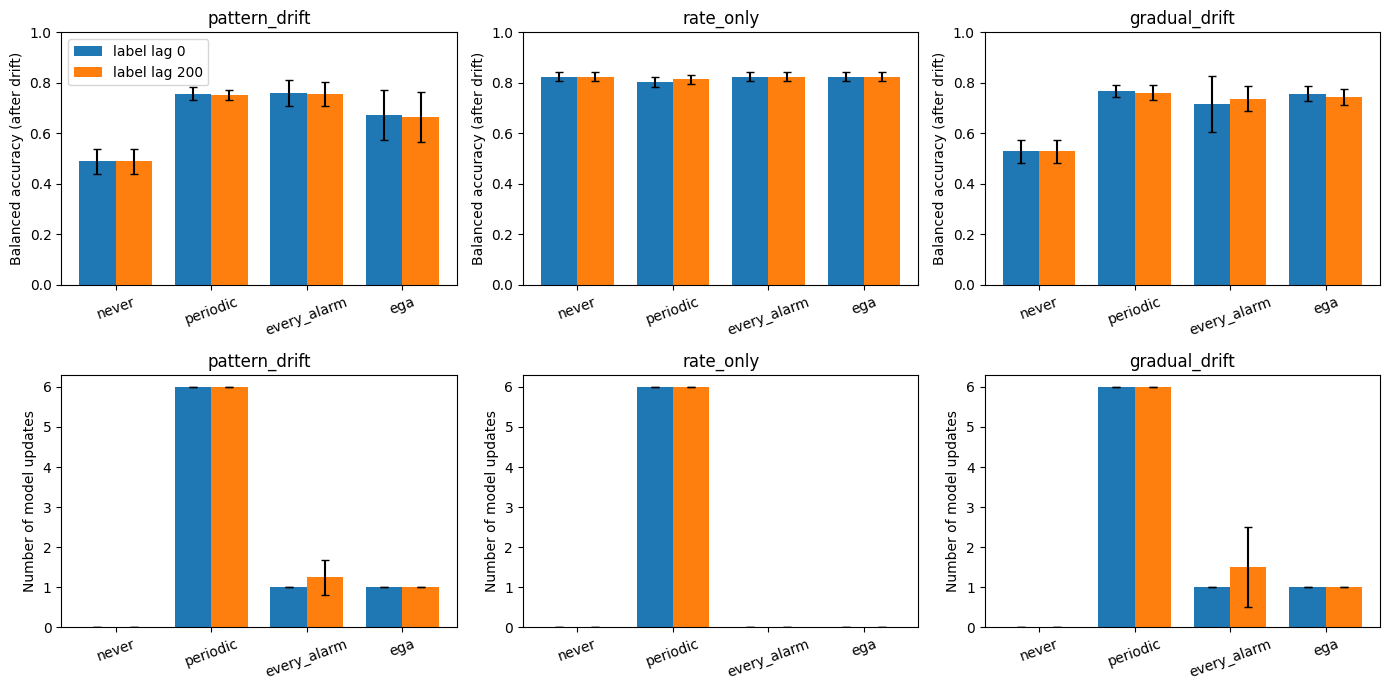

In [ ]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

base = "/content/drive/MyDrive/DriftWise"
path = f"{base}/results/step24_main_comparison.csv"
print("Step 24 results exist:", os.path.exists(path))

if os.path.exists(path):
    df = pd.read_csv(path)
    os.makedirs(f"{base}/results/tables", exist_ok=True)
    os.makedirs(f"{base}/results/plots", exist_ok=True)
    order = ["never", "periodic", "every_alarm", "ega"]

    # Table: mean ± std over seeds
    def fmt(g, col):
        return f"{g[col].mean():.3f} ± {g[col].std():.3f}"
    rows = []
    for (cond, lag, m), g in df.groupby(["condition", "lag", "method"]):
        rows.append({"stream": cond, "label lag": lag, "method": m,
                     "balanced acc": fmt(g, "balanced_acc"),
                     "worst-class recall": fmt(g, "worst_class_recall"),
                     "updates": f"{g['n_updates'].mean():.1f}",
                     "updates before drift": f"{g['updates_before_5000'].mean():.2f}",
                     "delay (records)": f"{g['first_update_delay'].mean():.0f}" if g['first_update_delay'].notna().any() else "-"})
    table = pd.DataFrame(rows)
    table["m_order"] = table["method"].map({m: i for i, m in enumerate(order)})
    table = table.sort_values(["stream", "label lag", "m_order"]).drop(columns="m_order")
    table.to_csv(f"{base}/results/tables/main_table.csv", index=False)
    with open(f"{base}/results/tables/main_table.md", "w") as f:
        f.write(table.to_markdown(index=False))
    display(table)

    # Figure: balanced accuracy and number of updates
    conds = ["pattern_drift", "rate_only", "gradual_drift"]
    fig, axes = plt.subplots(2, 3, figsize=(14, 7))
    for c, cond in enumerate(conds):
        for r, (metric, label) in enumerate([("balanced_acc", "Balanced accuracy (after drift)"),
                                              ("n_updates", "Number of model updates")]):
            ax, w = axes[r, c], 0.38
            for k, lag in enumerate(sorted(df.lag.unique())):
                g = df[(df.condition == cond) & (df.lag == lag)].groupby("method")[metric].agg(["mean", "std"]).reindex(order)
                ax.bar(np.arange(len(order)) + k * w, g["mean"], w, yerr=g["std"], capsize=3, label=f"label lag {lag}")
            ax.set_xticks(np.arange(len(order)) + w / 2)
            ax.set_xticklabels(order, rotation=20)
            ax.set_title(cond); ax.set_ylabel(label)
            if r == 0: ax.set_ylim(0, 1)
            if r == 0 and c == 0: ax.legend()
    plt.tight_layout()
    plt.savefig(f"{base}/results/plots/main_comparison.png", dpi=200, bbox_inches="tight")
    plt.show()
else:
    print("Run Step 24 first (it saves step24_main_comparison.csv).")

In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/DriftWise/results/step17_delayed_labels.csv")
sub = df[(df.condition == "pattern_drift") & (df.lag == 0) &
         (df.method.isin(["ega", "every_alarm"]))]

wide = sub.pivot(index="seed", columns="method",
                 values=["balanced_acc", "first_update_delay"])
wide.columns = [f"{a}_{b}" for a, b in wide.columns]
wide["gap_ega_minus_every"] = wide["balanced_acc_ega"] - wide["balanced_acc_every_alarm"]

display(wide.round(3).sort_values("gap_ega_minus_every"))

print("Seeds where EGA is worse by more than 0.05:",
      int((wide["gap_ega_minus_every"] < -0.05).sum()), "of", len(wide))
print("Correlation between EGA's update delay and its accuracy:",
      round(wide["first_update_delay_ega"].corr(wide["balanced_acc_ega"]), 2))

,balanced_acc_ega,balanced_acc_every_alarm,first_update_delay_ega,first_update_delay_every_alarm,gap_ega_minus_every
seed,,,,,
3,0.588,0.836,249.0,249.0,-0.248
9,0.655,0.823,249.0,249.0,-0.168
7,0.634,0.789,349.0,349.0,-0.154
5,0.660,0.740,249.0,249.0,-0.080
6,0.743,0.775,199.0,99.0,-0.031
2,0.772,0.783,599.0,599.0,-0.011
4,0.779,0.782,499.0,399.0,-0.003
8,0.725,0.718,499.0,199.0,0.007
1,0.783,0.768,549.0,449.0,0.016


Seeds where EGA is worse by more than 0.05: 4 of 10
Correlation between EGA's update delay and its accuracy: 0.7


trace what EGA accepted in the bad seeds

In [ ]:
import numpy as np, pandas as pd

def trace_ega(seed, start=4000, chunk=50, gate_every=100, T=1500,
              val_size=400, gap=50, sev_thr=0.06):
    X, y = make_stream(seed, "pattern_drift")
    n = len(y)
    model = fit_model(X[:start], y[:start])
    preds = np.zeros(n, dtype=int)
    adwin = new_adwin()
    in_ep, alarm_t, look = False, None, 0

    def post_pct(a, b):                  # % of records a..b-1 that come after the drift
        return round(100 * float((np.arange(a, b) >= 5000).mean()))

    for s in range(start, n, chunk):
        e = min(s + chunk, n)
        preds[s:e] = predict(model, X[s:e])
        t = e - 1
        fired = False
        for i in range(s, e):
            fired = adwin_step(adwin, int(preds[i] != y[i])) or fired
        if t < start + 700:
            continue
        if (not in_ep) and fired:
            in_ep, alarm_t, look = True, t, 0
        if in_ep and (t - alarm_t) % gate_every == 0:
            look += 1
            k = min(t + 1, start + 500) - start
            base_err = (preds[start:start + k] != y[start:start + k]).mean()
            recent_err = (preds[t - 199:t + 1] != y[t - 199:t + 1]).mean()
            pool = ["inc"] if (recent_err - base_err) < sev_thr else ["short", "long", "inc"]
            Xv, yv = X[t + 1 - val_size:t + 1], y[t + 1 - val_size:t + 1]
            te = t + 1 - val_size - gap
            p_cur = predict(model, Xv)
            best = None
            for name in pool:
                a = te - 600 if name == "long" else te - 300
                if name == "inc":
                    cand = incremental_update(model, X[a:te], y[a:te])
                else:
                    cand = fit_model(X[a:te], y[a:te])
                r = sequential_gate(yv, predict(cand, Xv), p_cur, look=look,
                                    alpha_total=0.05 / len(pool))
                if r["decision"] == "ACCEPT" and (best is None or r["est_balacc"] > best[1]):
                    best = (name, r["est_balacc"], a)
            if best is not None:
                name, est, a = best
                return {"seed": seed, "looks": look,
                        "accepted_at (records after drift)": t - 5000,
                        "pool": "+".join(pool), "accepted": name,
                        "train % post-drift": post_pct(a, te),
                        "validation % post-drift": post_pct(t + 1 - val_size, t + 1),
                        "gate est. gain": round(float(est), 3)}
            if t - alarm_t >= T:
                in_ep = False
                adwin = new_adwin()
    return {"seed": seed, "accepted": "none"}

trace = pd.DataFrame([trace_ega(sd) for sd in [3, 9, 7, 5, 1, 0]])
display(trace)

,seed,looks,accepted_at (records after drift),pool,accepted,train % post-drift,validation % post-drift,gate est. gain
0,3,1,249,short+long+inc,short,0,62,0.108
1,9,1,249,short+long+inc,long,0,62,0.191
2,7,1,349,short+long+inc,inc,0,88,0.320
3,5,1,249,short+long+inc,short,0,62,0.212
4,1,2,549,short+long+inc,short,33,100,0.287
5,0,2,349,short+long+inc,long,0,88,0.250


let EGA keep improving after its first accept

In [9]:
import numpy as np, pandas as pd

def run_ega_v2(X, y, lag=0, patience=None, start=4000, chunk=50, gate_every=100, T=1500,
               val_size=400, gap=50, sev_thr=0.06):
    """Same EGA loop as run_delayed("ega"), with one option:
       patience=None -> stop after the first accepted candidate (original behaviour)
       patience=k    -> keep gating after an accept; end the episode after k looks with no further accept"""
    n = len(y)
    model = fit_model(X[:start], y[:start])
    preds = np.zeros(n, dtype=int)
    adwin = new_adwin()
    in_ep, alarm_t, look = False, None, 0
    n_acc, streak = 0, 0
    updates = []

    for s in range(start, n, chunk):
        e = min(s + chunk, n)
        preds[s:e] = predict(model, X[s:e])
        t = e - 1
        tl = t - lag

        lo, hi = max(s - lag, start), e - lag
        fired = False
        for i in range(lo, max(hi, lo)):
            fired = adwin_step(adwin, int(preds[i] != y[i])) or fired
        if tl < start + 700:
            continue

        if (not in_ep) and fired:
            in_ep, alarm_t, look, n_acc, streak = True, tl, 0, 0, 0

        if in_ep and (tl - alarm_t) % gate_every == 0:
            look += 1
            k = min(tl + 1, start + 500) - start
            base_err = (preds[start:start + k] != y[start:start + k]).mean()
            recent_err = (preds[tl - 199:tl + 1] != y[tl - 199:tl + 1]).mean()
            pool = ["inc"] if (recent_err - base_err) < sev_thr else ["short", "long", "inc"]

            Xv, yv = X[tl + 1 - val_size:tl + 1], y[tl + 1 - val_size:tl + 1]
            te = tl + 1 - val_size - gap
            p_cur = predict(model, Xv)
            best = None
            for name in pool:
                if name == "short":
                    cand = fit_model(X[te - 300:te], y[te - 300:te])
                elif name == "long":
                    cand = fit_model(X[te - 600:te], y[te - 600:te])
                else:
                    cand = incremental_update(model, X[te - 300:te], y[te - 300:te])
                r = sequential_gate(yv, predict(cand, Xv), p_cur, look=look,
                                    alpha_total=0.05 / len(pool))
                if r["decision"] == "ACCEPT" and (best is None or r["est_balacc"] > best[1]["est_balacc"]):
                    best = (cand, r, name)

            if best is not None:
                model = best[0]; updates.append(t); n_acc += 1; streak = 0
                if patience is None:
                    in_ep = False; adwin = new_adwin()
            else:
                streak += 1
                if patience is not None and n_acc > 0 and streak >= patience:
                    in_ep = False; adwin = new_adwin()
                elif tl - alarm_t >= T:
                    in_ep = False; adwin = new_adwin()
            if in_ep and tl - alarm_t >= T:
                in_ep = False; adwin = new_adwin()

    ye, pe = y[5000:], preds[5000:]
    r0 = (pe[ye == 0] == 0).mean(); r1 = (pe[ye == 1] == 1).mean()
    after = [u for u in updates if u >= 5000]
    return {"balanced_acc": (r0 + r1) / 2, "worst_class_recall": min(r0, r1),
            "n_updates": len(updates),
            "first_update_delay": (after[0] - 5000) if after else np.nan}

rows = []
for seed in range(10):
    X, y = make_stream(seed, "pattern_drift")
    for label, pat in [("ega (stop at first accept)", None),
                       ("ega_v2 (keep improving)", 3)]:
        r = run_ega_v2(X, y, lag=0, patience=pat)
        r.update(method=label, seed=seed)
        rows.append(r)
v2 = pd.DataFrame(rows)

saved = pd.read_csv("/content/drive/MyDrive/DriftWise/results/step17_delayed_labels.csv")
saved = saved[(saved.condition == "pattern_drift") & (saved.lag == 0) &
              (saved.method.isin(["every_alarm", "never"]))]

cols = ["balanced_acc", "worst_class_recall", "n_updates", "first_update_delay"]
display(pd.concat([v2.groupby("method")[cols].mean(),
                   saved.groupby("method")[cols].mean()]).round(3))

ref = saved[saved.method == "every_alarm"].set_index("seed")["balanced_acc"]
for label in v2.method.unique():
    d = v2[v2.method == label].set_index("seed")["balanced_acc"] - ref
    print(f"{label}: mean gap vs every_alarm = {d.mean():+.3f}, "
          f"seeds worse by more than 0.05: {int((d < -0.05).sum())} of {len(d)}")

,balanced_acc,worst_class_recall,n_updates,first_update_delay
method,,,,
ega (stop at first accept),0.701,0.571,1.0,379.0
ega_v2 (keep improving),0.767,0.718,1.7,379.0
every_alarm,0.766,0.639,1.0,309.0
never,0.488,0.110,0.0,NaN


ega (stop at first accept): mean gap vs every_alarm = -0.065, seeds worse by more than 0.05: 4 of 10
ega_v2 (keep improving): mean gap vs every_alarm = +0.001, seeds worse by more than 0.05: 2 of 10


test on fresh seeds, on pattern drift and on rate-only

In [ ]:
import numpy as np, pandas as pd
from scipy import stats

rows = []
for cond in ["pattern_drift", "rate_only"]:
    for seed in range(10, 40):                       # fresh seeds, not used in the diagnosis
        X, y = make_stream(seed, cond)
        res = {
            "ega (stop at first accept)": run_ega_v2(X, y, lag=0, patience=None),
            "ega_v2 (keep improving)":    run_ega_v2(X, y, lag=0, patience=3),
            "every_alarm":                run_delayed("every_alarm", X, y, lag=0),
        }
        for m, r in res.items():
            rows.append({**r, "condition": cond, "method": m, "seed": seed})
fresh = pd.DataFrame(rows)

cols = ["balanced_acc", "worst_class_recall", "n_updates"]
display(fresh.groupby(["condition", "method"])[cols].agg(["mean", "std"]).round(3))

print("\nPaired difference per seed, minus every_alarm (mean, 95% CI):")
for cond in fresh.condition.unique():
    for m in ["ega (stop at first accept)", "ega_v2 (keep improving)"]:
        for metric in ["balanced_acc", "worst_class_recall"]:
            a = fresh[(fresh.condition == cond) & (fresh.method == m)].set_index("seed")[metric]
            b = fresh[(fresh.condition == cond) & (fresh.method == "every_alarm")].set_index("seed")[metric]
            d = (a - b).dropna()
            sd = d.std(ddof=1)
            h = stats.t.ppf(0.975, len(d) - 1) * sd / np.sqrt(len(d)) if sd > 0 else 0.0
            print(f"{cond:14s} {m:27s} {metric:19s} {d.mean():+.3f} [{d.mean()-h:+.3f}, {d.mean()+h:+.3f}]")

balanced_acc         \
                                                 mean    std   
condition     method                                           
pattern_drift ega (stop at first accept)        0.684  0.098   
              ega_v2 (keep improving)           0.773  0.039   
              every_alarm                       0.744  0.067   
rate_only     ega (stop at first accept)        0.830  0.011   
              ega_v2 (keep improving)           0.830  0.011   
              every_alarm                       0.830  0.011   

                                         worst_class_recall        n_updates  \
                                                       mean    std      mean   
condition     method                                                           
pattern_drift ega (stop at first accept)              0.560  0.200     0.967   
              ega_v2 (keep improving)                 0.713  0.071     1.633   
              every_alarm                             0.649  0.148     0.967   
rate_only     ega (stop at first accept)              0.790  0.039     0.000   
              ega_v2 (keep improving)                 0.790  0.039     0.000   
              every_alarm                             0.790  0.039     0.000   

                                                 
                                            std  
condition     method                             
pattern_drift ega (stop at first accept)  0.183  
              ega_v2 (keep improving)     0.809  
              every_alarm                 0.183  
rate_only     ega (stop at first accept)  0.000  
              ega_v2 (keep improving)     0.000  
              every_alarm                 0.000


Paired difference per seed, minus every_alarm (mean, 95% CI):
pattern_drift  ega (stop at first accept)  balanced_acc        -0.061 [-0.104, -0.017]
pattern_drift  ega (stop at first accept)  worst_class_recall  -0.089 [-0.183, +0.005]
pattern_drift  ega_v2 (keep improving)     balanced_acc        +0.029 [+0.009, +0.048]
pattern_drift  ega_v2 (keep improving)     worst_class_recall  +0.064 [+0.021, +0.106]
rate_only      ega (stop at first accept)  balanced_acc        +0.000 [+0.000, +0.000]
rate_only      ega (stop at first accept)  worst_class_recall  +0.000 [+0.000, +0.000]
rate_only      ega_v2 (keep improving)     balanced_acc        +0.000 [+0.000, +0.000]
rate_only      ega_v2 (keep improving)     worst_class_recall  +0.000 [+0.000, +0.000]


compare ega_v2 with ungated “retrain again later” baselines

In [10]:
import numpy as np, pandas as pd
from scipy import stats

def run_retrain_schedule(X, y, offsets=(0, 500), lag=0, start=4000, chunk=50, window=300):
    """No gate. After an alarm, retrain on the newest `window` labels at each offset (records after the alarm)."""
    n = len(y)
    model = fit_model(X[:start], y[:start])
    preds = np.zeros(n, dtype=int)
    adwin = new_adwin()
    in_ep, alarm_t = False, None
    updates = []
    for s in range(start, n, chunk):
        e = min(s + chunk, n)
        preds[s:e] = predict(model, X[s:e])
        t = e - 1
        tl = t - lag
        lo, hi = max(s - lag, start), e - lag
        fired = False
        for i in range(lo, max(hi, lo)):
            fired = adwin_step(adwin, int(preds[i] != y[i])) or fired
        if tl < start + 700:
            continue
        if (not in_ep) and fired:
            in_ep, alarm_t = True, tl
        if in_ep:
            gone = tl - alarm_t
            if gone in offsets:
                model = fit_model(X[tl - window + 1:tl + 1], y[tl - window + 1:tl + 1])
                updates.append(t)
            if gone >= max(offsets):
                in_ep = False
                adwin = new_adwin()
    ye, pe = y[5000:], preds[5000:]
    r0 = (pe[ye == 0] == 0).mean(); r1 = (pe[ye == 1] == 1).mean()
    after = [u for u in updates if u >= 5000]
    return {"balanced_acc": (r0 + r1) / 2, "worst_class_recall": min(r0, r1),
            "n_updates": len(updates),
            "first_update_delay": (after[0] - 5000) if after else np.nan}

rows = []
for seed in range(10, 40):                           # same fresh seeds as the last step
    X, y = make_stream(seed, "pattern_drift")
    res = {
        "every_alarm (retrain once)":            run_delayed("every_alarm", X, y, lag=0),
        "retrain at alarm and +500 (no gate)":   run_retrain_schedule(X, y, offsets=(0, 500)),
        "retrain at alarm, +300, +600 (no gate)": run_retrain_schedule(X, y, offsets=(0, 300, 600)),
        "ega_v2 (gated, keep improving)":        run_ega_v2(X, y, lag=0, patience=3),
    }
    for m, r in res.items():
        rows.append({**r, "method": m, "seed": seed})
cmp_df = pd.DataFrame(rows)

cols = ["balanced_acc", "worst_class_recall", "n_updates"]
display(cmp_df.groupby("method")[cols].agg(["mean", "std"]).round(3))

print("\nega_v2 minus each ungated baseline (paired by seed, mean and 95% CI):")
v2 = cmp_df[cmp_df.method == "ega_v2 (gated, keep improving)"].set_index("seed")
for m in cmp_df.method.unique():
    if m.startswith("ega_v2"):
        continue
    b = cmp_df[cmp_df.method == m].set_index("seed")
    for metric in ["balanced_acc", "worst_class_recall"]:
        d = (v2[metric] - b[metric]).dropna()
        sd = d.std(ddof=1)
        h = stats.t.ppf(0.975, len(d) - 1) * sd / np.sqrt(len(d)) if sd > 0 else 0.0
        print(f"vs {m:40s} {metric:19s} {d.mean():+.3f} [{d.mean()-h:+.3f}, {d.mean()+h:+.3f}]")

balanced_acc        worst_class_recall  \
                                               mean    std               mean   
method                                                                          
ega_v2 (gated, keep improving)                0.773  0.039              0.713   
every_alarm (retrain once)                    0.744  0.067              0.649   
retrain at alarm and +500 (no gate)           0.757  0.069              0.671   
retrain at alarm, +300, +600 (no gate)        0.772  0.034              0.708   

                                              n_updates         
                                          std      mean    std  
method                                                          
ega_v2 (gated, keep improving)          0.071     1.633  0.809  
every_alarm (retrain once)              0.148     0.967  0.183  
retrain at alarm and +500 (no gate)     0.145     1.933  0.365  
retrain at alarm, +300, +600 (no gate)  0.075     2.900  0.548


ega_v2 minus each ungated baseline (paired by seed, mean and 95% CI):
vs every_alarm (retrain once)               balanced_acc        +0.029 [+0.009, +0.048]
vs every_alarm (retrain once)               worst_class_recall  +0.064 [+0.021, +0.106]
vs retrain at alarm and +500 (no gate)      balanced_acc        +0.016 [-0.011, +0.042]
vs retrain at alarm and +500 (no gate)      worst_class_recall  +0.042 [-0.018, +0.102]
vs retrain at alarm, +300, +600 (no gate)   balanced_acc        +0.001 [-0.014, +0.015]
vs retrain at alarm, +300, +600 (no gate)   worst_class_recall  +0.005 [-0.032, +0.043]


does this hold on gradual drift and with delayed labels?

In [ ]:
import numpy as np, pandas as pd
from scipy import stats

def make_stream_gradual(seed, n=10000, start_d=5000, width=2000):
    r = np.random.default_rng(seed)
    w = np.clip((np.arange(n) - start_d) / width, 0, 1)         # 0 -> 1 ramp
    y = (r.random(n) < (0.05 + 0.15 * w)).astype(int)
    X = r.normal(size=(n, 2))
    use_new = r.random(n) < w                                    # per record: new pattern with prob w
    X[~use_new, 0] += 2.0 * y[~use_new]
    X[use_new, 1] += 2.0 * y[use_new]
    return X, y

V2 = "ega_v2 (gated)"
B1 = "every_alarm (retrain once)"
B3 = "retrain at alarm, +300, +600 (no gate)"

combos = [("pattern_drift", 200), ("gradual_drift", 0), ("gradual_drift", 200)]
rows = []
for cond, lag in combos:
    for seed in range(10, 30):                       # 20 seeds
        X, y = make_stream_gradual(seed) if cond == "gradual_drift" else make_stream(seed, cond)
        res = {
            B1: run_delayed("every_alarm", X, y, lag=lag),
            B3: run_retrain_schedule(X, y, offsets=(0, 300, 600), lag=lag),
            V2: run_ega_v2(X, y, lag=lag, patience=3),
        }
        for m, r in res.items():
            rows.append({**r, "condition": cond, "lag": lag, "method": m, "seed": seed})
all3 = pd.DataFrame(rows)

cols = ["balanced_acc", "worst_class_recall", "n_updates"]
display(all3.groupby(["condition", "lag", "method"])[cols].mean().round(3))

def paired(a, b, metric):
    d = (a[metric] - b[metric]).dropna()
    sd = d.std(ddof=1)
    h = stats.t.ppf(0.975, len(d) - 1) * sd / np.sqrt(len(d)) if sd > 0 else 0.0
    return f"{d.mean():+.3f} [{d.mean()-h:+.3f}, {d.mean()+h:+.3f}]"

out = []
for cond, lag in combos:
    sub = all3[(all3.condition == cond) & (all3.lag == lag)]
    a = sub[sub.method == V2].set_index("seed")
    for base in [B1, B3]:
        b = sub[sub.method == base].set_index("seed")
        out.append({"condition": cond, "lag": lag, "ega_v2 minus": base,
                    **{c: paired(a, b, c) for c in cols}})
print("\nega_v2 minus baseline (paired by seed, mean [95% CI]):")
pd.set_option("display.max_colwidth", None, "display.width", 250)
display(pd.DataFrame(out))

balanced_acc  \
condition     lag method                                                 
gradual_drift 0   ega_v2 (gated)                                 0.768   
                  every_alarm (retrain once)                     0.740   
                  retrain at alarm, +300, +600 (no gate)         0.758   
              200 ega_v2 (gated)                                 0.756   
                  every_alarm (retrain once)                     0.737   
                  retrain at alarm, +300, +600 (no gate)         0.747   
pattern_drift 200 ega_v2 (gated)                                 0.764   
                  every_alarm (retrain once)                     0.738   
                  retrain at alarm, +300, +600 (no gate)         0.766   

                                                          worst_class_recall  \
condition     lag method                                                       
gradual_drift 0   ega_v2 (gated)                                       0.721   
                  every_alarm (retrain once)                           0.673   
                  retrain at alarm, +300, +600 (no gate)               0.691   
              200 ega_v2 (gated)                                       0.695   
                  every_alarm (retrain once)                           0.673   
                  retrain at alarm, +300, +600 (no gate)               0.679   
pattern_drift 200 ega_v2 (gated)                                       0.697   
                  every_alarm (retrain once)                           0.662   
                  retrain at alarm, +300, +600 (no gate)               0.705   

                                                          n_updates  
condition     lag method                                             
gradual_drift 0   ega_v2 (gated)                               1.15  
                  every_alarm (retrain once)                   1.00  
                  retrain at alarm, +300, +600 (no gate)       3.00  
              200 ega_v2 (gated)                               1.15  
                  every_alarm (retrain once)                   1.55  
                  retrain at alarm, +300, +600 (no gate)       3.45  
pattern_drift 200 ega_v2 (gated)                               1.70  
                  every_alarm (retrain once)                   1.10  
                  retrain at alarm, +300, +600 (no gate)       3.30


ega_v2 minus baseline (paired by seed, mean [95% CI]):


,condition,lag,ega_v2 minus,balanced_acc,worst_class_recall,n_updates
0,pattern_drift,200,every_alarm (retrain once),"+0.026 [+0.002, +0.049]","+0.035 [-0.010, +0.080]","+0.600 [+0.216, +0.984]"
1,pattern_drift,200,"retrain at alarm, +300, +600 (no gate)","-0.002 [-0.019, +0.014]","-0.007 [-0.055, +0.041]","-1.600 [-2.176, -1.024]"
2,gradual_drift,0,every_alarm (retrain once),"+0.028 [-0.007, +0.064]","+0.048 [-0.002, +0.098]","+0.150 [-0.021, +0.321]"
3,gradual_drift,0,"retrain at alarm, +300, +600 (no gate)","+0.010 [-0.005, +0.025]","+0.030 [-0.005, +0.065]","-1.850 [-2.021, -1.679]"
4,gradual_drift,200,every_alarm (retrain once),"+0.019 [+0.001, +0.037]","+0.022 [-0.005, +0.049]","-0.400 [-0.890, +0.090]"
5,gradual_drift,200,"retrain at alarm, +300, +600 (no gate)","+0.009 [-0.005, +0.023]","+0.016 [-0.017, +0.048]","-2.300 [-2.806, -1.794]"


In [ ]:
import os
base = "/content/drive/MyDrive/DriftWise"
os.makedirs(f"{base}/results", exist_ok=True)

to_save = {
    "fresh":  "ega_v2_fresh_seeds_pattern_and_rate_only.csv",
    "cmp_df": "ega_v2_vs_schedules_pattern_lag0.csv",
    "all3":   "ega_v2_vs_baselines_gradual_and_delayed.csv",
}
for var, fname in to_save.items():
    if var in globals():
        globals()[var].to_csv(f"{base}/results/{fname}", index=False)
        print("Saved:", fname, globals()[var].shape)
    else:
        print(f"'{var}' is not in memory (session restarted?), skipped")

Saved: ega_v2_fresh_seeds_pattern_and_rate_only.csv (180, 8)
Saved: ega_v2_vs_schedules_pattern_lag0.csv (120, 7)
Saved: ega_v2_vs_baselines_gradual_and_delayed.csv (180, 9)


does a single, well-timed retrain match ega_v2

In [ ]:
import numpy as np, pandas as pd
from scipy import stats

base = "/content/drive/MyDrive/DriftWise"
prev = pd.read_csv(f"{base}/results/ega_v2_vs_schedules_pattern_lag0.csv")
V2 = "ega_v2 (gated, keep improving)"
v2 = prev[prev.method == V2].set_index("seed")

variants = {
    "1 retrain at alarm+300 (300 labels)": dict(offsets=(300,), window=300),
    "1 retrain at alarm+600 (300 labels)": dict(offsets=(600,), window=300),
    "1 retrain at alarm+600 (600 labels)": dict(offsets=(600,), window=600),
}
rows = []
for seed in range(10, 40):                       # same fresh seeds as before
    X, y = make_stream(seed, "pattern_drift")
    for name, kw in variants.items():
        r = run_retrain_schedule(X, y, lag=0, **kw)
        rows.append({**r, "method": name, "seed": seed})
single = pd.DataFrame(rows)
single.to_csv(f"{base}/results/single_delayed_retrain_pattern_lag0.csv", index=False)

cols = ["balanced_acc", "worst_class_recall", "n_updates"]
summary = pd.concat([single.groupby("method")[cols].mean(),
                     v2[cols].mean().to_frame(V2).T]).round(3)
display(summary)

def paired(a, b, metric):
    d = (a[metric] - b[metric]).dropna()
    sd = d.std(ddof=1)
    h = stats.t.ppf(0.975, len(d) - 1) * sd / np.sqrt(len(d)) if sd > 0 else 0.0
    return f"{d.mean():+.3f} [{d.mean()-h:+.3f}, {d.mean()+h:+.3f}]"

out = []
for name in variants:
    b = single[single.method == name].set_index("seed")
    out.append({"ega_v2 minus": name, **{c: paired(v2, b, c) for c in cols}})
print("\nega_v2 minus each single-retrain baseline (paired by seed, mean [95% CI]):")
pd.set_option("display.max_colwidth", None, "display.width", 250)
display(pd.DataFrame(out))

,balanced_acc,worst_class_recall,n_updates
1 retrain at alarm+300 (300 labels),0.762,0.693,0.967
1 retrain at alarm+600 (300 labels),0.739,0.664,0.967
1 retrain at alarm+600 (600 labels),0.757,0.682,0.967
"ega_v2 (gated, keep improving)",0.773,0.713,1.633



ega_v2 minus each single-retrain baseline (paired by seed, mean [95% CI]):


,ega_v2 minus,balanced_acc,worst_class_recall,n_updates
0,1 retrain at alarm+300 (300 labels),"+0.011 [-0.003, +0.024]","+0.020 [-0.012, +0.052]","+0.667 [+0.384, +0.950]"
1,1 retrain at alarm+600 (300 labels),"+0.034 [+0.019, +0.049]","+0.049 [+0.013, +0.085]","+0.667 [+0.384, +0.950]"
2,1 retrain at alarm+600 (600 labels),"+0.016 [+0.001, +0.030]","+0.031 [-0.002, +0.063]","+0.667 [+0.384, +0.950]"


In [11]:
import time
import numpy as np, pandas as pd

# Count every model that gets trained and every gate test, without changing how anything works
cost = {"fits": 0, "gate_calls": 0, "val_rows": 0}
if "_orig" not in globals():
    _orig = dict(fit=fit_model, inc=incremental_update, gate=sequential_gate)

def fit_model(X, y):
    cost["fits"] += 1
    return _orig["fit"](X, y)

def incremental_update(model, X, y):
    cost["fits"] += 1
    return _orig["inc"](model, X, y)

def sequential_gate(y, *a, **k):
    cost["gate_calls"] += 1
    cost["val_rows"] += len(y)
    return _orig["gate"](y, *a, **k)

variants = {
    "every_alarm (retrain once)":     lambda X, y: run_delayed("every_alarm", X, y, lag=0),
    "1 retrain at alarm+300":         lambda X, y: run_retrain_schedule(X, y, offsets=(300,), window=300),
    "retrain at alarm, +300, +600":   lambda X, y: run_retrain_schedule(X, y, offsets=(0, 300, 600)),
    "ega_v2 (gated)":                 lambda X, y: run_ega_v2(X, y, lag=0, patience=3),
}
rows = []
for seed in range(10, 30):                       # 20 fresh seeds, pattern drift, no label delay
    X, y = make_stream(seed, "pattern_drift")
    for name, f in variants.items():
        for k in cost:
            cost[k] = 0
        t0 = time.perf_counter()
        r = f(X, y)
        rows.append({"method": name, "seed": seed, "balanced_acc": r["balanced_acc"],
                     "updates": r["n_updates"], "models_trained": cost["fits"],
                     "gate_tests": cost["gate_calls"], "validation_labels_used": cost["val_rows"],
                     "seconds": time.perf_counter() - t0})
cost_df = pd.DataFrame(rows)
cols = ["balanced_acc", "updates", "models_trained", "gate_tests", "validation_labels_used", "seconds"]
pd.set_option("display.width", 250, "display.max_columns", 20)
display(cost_df.groupby("method")[cols].mean().round(2))
cost_df.to_csv("/content/drive/MyDrive/DriftWise/results/ega_v2_cost_comparison.csv", index=False)
print("Saved: ega_v2_cost_comparison.csv")

,balanced_acc,updates,models_trained,gate_tests,validation_labels_used,seconds
method,,,,,,
1 retrain at alarm+300,0.77,1.00,2.0,0.0,0.0,0.07
ega_v2 (gated),0.78,1.65,16.6,15.6,6240.0,0.15
every_alarm (retrain once),0.74,1.00,2.0,0.0,0.0,0.07
"retrain at alarm, +300, +600",0.77,3.00,4.0,0.0,0.0,0.08


Saved: ega_v2_cost_comparison.csv
